# 14 · XGBoost and random-forest rerankers: learning which candidate is right

**The question this step answers:** notebook 13 turned every (account, candidate) pair into 27 numbers. Can a model trained on those numbers pick the right group more often, and more *confidently*, than the two baselines? And does it need more training data, or more PCA features?

**Where it sits in the pipeline:**

```
account name -> shortlist of 10 (07, 12) -> 10 rows of 27 numbers (13) -> a tree model scores each row (this step)
             -> the highest row is the pick -> calibration on dev (09) -> auto or review
```

**The code:**
- `src/d1/mapper/methods/rerankers.py`: `PairwiseReranker`, one class for both models (`xgboost_model`, `random_forest_model`), plus `company_holdout`, `top1_share` and `permutation_importance`;
- `src/d1/mapper/train.py`: trains and calibrates them like every other method (`python -m d1.mapper.train --method xgboost`);
- `src/d1/evaluation/learning_curve.py`: refits on 25/50/75/100% of the train companies (`python -m d1.evaluation.learning_curve --method xgboost random_forest`).

Both models are judged exactly like the baselines: the same shortlists, the same calibration on dev, the same pooled 98% bar.

*Running this notebook loads bge-m3, maps dev with the four trained methods and refits XGBoost four times (for section 2 and section 7): about five minutes.*

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from d1.config import load_config
from d1.datagen.schema import read_jsonl
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.metrics import bootstrap_ci, paired_bootstrap_diff
from d1.evaluation.plotting import GRID, INK, INK_2, METHOD_COLORS, SOURCE_COLORS, SURFACE, apply_style, pct
from d1.mapper.embed import MemoEmbedder, SentenceTransformerEmbedder
from d1.mapper.features import PairFeaturizer
from d1.mapper.methods.base import accounts_from_rows
from d1.mapper.methods.rerankers import PairwiseReranker, xgboost_model
from d1.mapper.pipeline import Mapper
from d1.mapper.train import calibrate_on_dev

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 60)
K = config.models.mapping.candidates_k
TARGET = config.models.mapping.target_precision
METHODS = ["fuzzy", "embeddings", "xgboost", "random_forest"]

train = read_jsonl(config.data.generated_dir / "train.jsonl")
dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
companies = np.array([r.company_id for r in dev])

# One bge-m3 for all four methods, remembering every vector it makes.
embedder = MemoEmbedder(SentenceTransformerEmbedder(config.models.embedding_model))
mappers = {m: Mapper.from_artifacts(config, m, embedder_factory=lambda name: embedder) for m in METHODS}
retriever = mappers["xgboost"].retriever

start = time.time()
dev_accounts = accounts_from_rows(dev)
dev_lists = retriever.top_k([r.name for r in dev], K)
decisions = {m: mapper.map(dev_accounts, shortlists=dev_lists) for m, mapper in mappers.items()}
right = {m: np.array([d.chosen_code == r.target_code for d, r in zip(decisions[m], dev)]) for m in METHODS}
auto = {m: np.array([d.decision_path == "auto" for d in decisions[m]]) for m in METHODS}
print(f"{len(dev):,} dev accounts mapped by {len(METHODS)} trained methods in {time.time() - start:.0f} s")

/Users/vincenzovantornout/Desktop/Work Projects/Work Projects/Data & AI Resume/D1 - Consolidation Copilot/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1110 12:48:44.650000 31464 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-m3'.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 57012.79it/s]

3,500 dev accounts mapped by 4 trained methods in 16 s


## 1. One account, re-ranked

The account notebook 13 followed: **"En-cours chantier Uccle - Av. Brugmann"**, code 320200, right group **320** *Work in Progress*. The signals disagreed: the cosine put 320 third, 0.014 behind 370, and fuzzy preferred four other groups. But the code starts with 320, and 320 had the highest parent cosine.

Here is what each trained reranker makes of the same ten rows, and what every method then decides:

In [2]:
row = next(r for r in dev if r.name == "En-cours chantier Uccle - Av. Brugmann")
i = dev.index(row)
shortlist = dev_lists[i]
probs = {m: mappers[m].method.score([dev_accounts[i]], [shortlist])[0].scores for m in ("xgboost", "random_forest")}
table = pd.DataFrame({
    "candidate": [f"{c.code} {by_code[c.code].name_en[:34]}" for c in shortlist],
    "right?": ["✔" if c.code == row.target_code else "" for c in shortlist],
    "cosine (rank)": [f"{c.score:.3f} ({n})" for n, c in enumerate(shortlist, start=1)],
    "XGBoost": [probs["xgboost"][c.code] for c in shortlist],
    "random forest": [probs["random_forest"][c.code] for c in shortlist],
})
print(f"{row.name}  code {row.code}  right group {row.target_code}")
display(table.style.format({"XGBoost": "{:.3f}", "random forest": "{:.3f}"}).hide(axis="index"))
display(pd.DataFrame([{
    "method": m, "pick": decisions[m][i].chosen_code, "right?": "✔" if right[m][i] else "✘",
    "confidence": decisions[m][i].confidence, "threshold": mappers[m].thresholds.t_auto, "decision": decisions[m][i].decision_path,
} for m in METHODS]).style.format({"confidence": "{:.3f}", "threshold": "{:.3f}"}).hide(axis="index"))

En-cours chantier Uccle - Av. Brugmann  code 320200  right group 320


candidate,right?,cosine (rank),XGBoost,random forest
370 Contracts in Progress - Acquisitio,,0.458 (1),0.000,0.052
717 Increase (Decrease) in Contracts i,,0.445 (2),0.000,0.030
320 Work in Progress - Acquisition Val,✔,0.444 (3),1.000,0.906
221 Buildings,,0.430 (4),0.000,0.015
371 Contracts in Progress - Profit Rec,,0.430 (5),0.000,0.019
632 Amounts Written Off Contracts in P,,0.423 (6),0.000,0.015
712 Increase (Decrease) in Stocks of W,,0.422 (7),0.000,0.033
426 Advance Payments on Contract in Pr,,0.419 (8),0.000,0.011
491 Accrued Income,,0.417 (9),0.000,0.009
499 Suspense Accounts,,0.417 (10),0.000,0.012


method,pick,right?,confidence,threshold,decision
fuzzy,160,✘,0.295,0.876,review
embeddings,370,✘,0.216,0.928,review
xgboost,320,✔,0.988,0.843,auto
random_forest,320,✔,0.981,0.815,auto


1. **XGBoost gives 320 a probability of 1.000** and all nine others 0.000 (rounded). The random forest agrees, a little less sharply (0.906 for 320, at most 0.052 for the others).
2. **Why so sure:** on train, a 6-digit code that starts with the candidate's code was *always* the right group (PCMN-style and LLM codes). The model learned that `code_prefix_match = 1` together with `n_digits = 6` settles it, whatever the cosine says.
3. **Calibration** turns that into a confidence: 0.988 for XGBoost and 0.981 for the forest. Both are above their thresholds (0.843 and 0.815), so the account is **auto-mapped, correctly.**
4. **The baselines** pick 370 (embeddings, confidence 0.216) and 160 (fuzzy, 0.295). Both are wrong, and both are sent to review, which is the safe outcome.

This one account shows the whole result in small: **the rerankers win mostly where the account code gives the answer away.** Sections 4 and 7 measure how much of the gain that is.

## 2. How the models were trained

`PairwiseReranker.fit` on the 11,999 train accounts:
1. **`company_holdout`** sets aside 10% of the train *companies* of each source (20 rule-based and 4 LLM-written, 1,200 accounts), never dev. Whole companies, because a company's accounts look alike.
2. **The featurizer's PCA** and the model are fitted on the other 90%: 10,799 accounts, 107,990 pairs, one right row per covered account.
3. **XGBoost adds trees until the hold-out stops improving** (50 trees without a better log loss), then keeps the best number. The random forest always grows 500 trees.
4. **Feature importance** is measured on the hold-out (section 6).

First, a check that training is repeatable: the train shortlists, then XGBoost refitted from scratch and compared with the saved model.

train shortlists in 21 s


refitted twice in 13 s


refit vs refit, same inputs : other pick on 0 of 3,500 dev accounts, largest score difference 0


refit vs saved model        : other pick on 72 of 3,500 dev accounts, largest score difference 0.26
of the 72 accounts with another pick, the saved model auto-mapped 0; trees: saved 775, refit 766


,fitted on (accounts),pairs,held-out companies,held-out accounts,top-1 on hold-out,trees
xgboost,"10,799","107,990",24,"1,200",96.3%,775
random_forest,"10,799","107,990",24,"1,200",96.0%,500


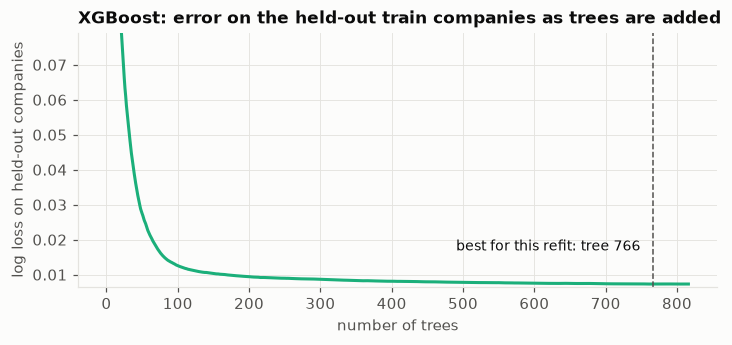

In [3]:
start = time.time()
train_lists = retriever.top_k([r.name for r in train], K)
print(f"train shortlists in {time.time() - start:.0f} s")


def refit_xgboost(n_pca: int) -> PairwiseReranker:
    reranker = PairwiseReranker("xgboost", PairFeaturizer(retriever, chart, n_pca=n_pca), xgboost_model)
    reranker.fit(train, train_lists)
    return reranker


start = time.time()
refit = refit_xgboost(config.models.mapping.n_pca)
again = refit_xgboost(config.models.mapping.n_pca)
print(f"refitted twice in {time.time() - start:.0f} s")
saved = mappers["xgboost"].method


def compare(a_method, b_method, label):
    pairs = list(zip(a_method.score(dev_accounts, dev_lists), b_method.score(dev_accounts, dev_lists)))
    differ = np.array([a.chosen_code != b.chosen_code for a, b in pairs])
    largest = max(abs(a.scores[c] - b.scores[c]) for a, b in pairs for c in a.scores)
    print(f"{label}: other pick on {differ.sum()} of {len(pairs):,} dev accounts, largest score difference {largest:.2g}")
    return differ


compare(refit, again, "refit vs refit, same inputs ")
differ = compare(refit, saved, "refit vs saved model        ")
print(f"of the {differ.sum()} accounts with another pick, the saved model auto-mapped {(differ & auto['xgboost']).sum()}; "
      f"trees: saved {saved.fit_info['trees']}, refit {refit.fit_info['trees']}")
display(pd.DataFrame({m: mappers[m].method.fit_info for m in ("xgboost", "random_forest")}).T
        .rename(columns={"train_accounts": "fitted on (accounts)", "train_pairs": "pairs", "holdout_companies": "held-out companies",
                         "holdout_accounts": "held-out accounts", "holdout_top1": "top-1 on hold-out", "trees": "trees"})
        .style.format({"top-1 on hold-out": "{:.1%}", "fitted on (accounts)": "{:,.0f}", "pairs": "{:,.0f}", "held-out companies": "{:.0f}",
                       "held-out accounts": "{:,.0f}", "trees": "{:.0f}"}))

loss = refit.model.evals_result()["validation_0"]["logloss"]
best = refit.model.best_iteration
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(np.arange(1, len(loss) + 1), loss, color=METHOD_COLORS["xgboost"])
ax.axvline(best + 1, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(f"best for this refit: tree {best + 1}", (best + 1, loss[best]), xytext=(-8, 22), textcoords="offset points", ha="right", fontsize=9, color=INK)
ax.set_xlabel("number of trees")
ax.set_ylabel("log loss on held-out companies")
ax.set_ylim(min(loss) * 0.9, loss[20])
ax.set_title("XGBoost: error on the held-out train companies as trees are added")
plt.show()

- **The saved XGBoost stopped at 775 trees.** The plan's ceiling of 600 would have cut it short: in a first run it was still improving at tree 588. The ceiling is now 2,000, and early stopping chooses.
- **The loss curve:** the error on the held-out companies falls steeply over the first hundred trees, then flattens. Past the best point, more trees would only fit the training companies more closely.
- **Top-1 on the hold-out is 96%**, higher than on dev (section 3), because train is 83% rule-based and dev only 57%.

**Is training repeatable?** Yes, on the same inputs: two refits in this notebook agree exactly, on every score. **But the refit is not the saved model.** It stopped at 766 trees instead of 775, and picks differently on 72 of the 3,500 dev accounts. The cause is in the inputs, not the model:
1. bge-m3's vector for a name changes by up to 0.0000002 depending on which other names share its encoding batch (checked: the same names in the same order give identical vectors). This notebook encodes in another order than `train.py`.
2. XGBoost first sorts every feature into 256 bins. A change that small can move a bin edge, and so a split, in an early tree.
3. Each tree corrects the trees before it, so one different early split changes everything after it.

**What it changes in the results:** almost nothing. Top-1 and the auto share are the same to within an account (section 7), and the 72 accounts whose pick flips are uncertain ones: the saved model auto-mapped none of them. **What it means for the project:** a saved model is the reference, and the evaluation always loads it rather than retraining. Results are quoted with intervals, never to the last account.

## 3. The result on dev: four methods, one bar

Every method is calibrated on dev the same way, and auto-maps where its calibrated confidence keeps dev precision at 98% or more (pooled over all accounts). The intervals resample whole dev companies (70 of them).

In [4]:
def ci(values):
    return bootstrap_ci(lambda idx: values[idx].mean(), len(dev), groups=companies)


rows = []
for m in METHODS:
    a, r = auto[m], right[m]
    lo, hi = ci(a)
    tlo, thi = ci(r)
    rows.append({"method": m, "top-1": r.mean(), "top-1 95%": f"{tlo:.1%} – {thi:.1%}", "auto-mapped": a.mean(),
                 "auto 95%": f"{lo:.1%} – {hi:.1%}", "precision of auto": r[a].mean() if a.any() else np.nan,
                 "threshold": mappers[m].thresholds.t_auto})
results = pd.DataFrame(rows).set_index("method")
display(results.style.format({"top-1": "{:.1%}", "auto-mapped": "{:.1%}", "precision of auto": "{:.1%}", "threshold": "{:.3f}"}))

pairs = [("xgboost", "embeddings"), ("random_forest", "embeddings"), ("xgboost", "random_forest")]
diffs = []
for a, b in pairs:
    for label, values in (("auto-mapped", auto), ("top-1", right)):
        d, lo, hi = paired_bootstrap_diff(values[a], values[b], groups=companies)
        diffs.append({"comparison": f"{a} − {b}", "measure": label, "difference": d * 100, "95% interval": f"{lo * 100:+.1f} to {hi * 100:+.1f}"})
display(pd.DataFrame(diffs).style.format({"difference": "{:+.1f} pts"}).hide(axis="index"))

,top-1,top-1 95%,auto-mapped,auto 95%,precision of auto,threshold
method,,,,,,
fuzzy,57.9%,49.5% – 66.0%,31.6%,25.5% – 37.4%,98.6%,0.876
embeddings,70.3%,64.9% – 75.6%,32.1%,27.1% – 36.9%,98.0%,0.928
xgboost,84.9%,81.0% – 88.8%,78.8%,72.5% – 84.9%,98.0%,0.843
random_forest,84.1%,80.0% – 88.2%,78.1%,71.7% – 84.1%,98.0%,0.815


comparison,measure,difference,95% interval
xgboost − embeddings,auto-mapped,+46.7 pts,+41.9 to +51.3
xgboost − embeddings,top-1,+14.7 pts,+10.9 to +18.5
random_forest − embeddings,auto-mapped,+46.0 pts,+41.0 to +50.6
random_forest − embeddings,top-1,+13.8 pts,+10.0 to +17.8
xgboost − random_forest,auto-mapped,+0.7 pts,+0.0 to +1.4
xgboost − random_forest,top-1,+0.8 pts,+0.4 to +1.3


- **Both rerankers auto-map about 78% of dev at 98% precision, against 32% for either baseline.** That's +46.7 points for XGBoost over the embeddings baseline (interval +41.9 to +51.3), and +14.7 points of top-1.
- **XGBoost and the forest are nearly tied:** XGBoost is ahead by 0.7 points of auto share (+0.0 to +1.4) and 0.8 points of top-1 (+0.4 to +1.3). Those are the *paired* intervals, on the same accounts, so the luck of which companies were drawn cancels out. That's why they are much narrower than each method's own interval.
- **The thresholds differ** (0.843, 0.815) because each method's raw scores have their own scale. Calibration maps both onto "chance of being right", and the 98% bar is the same for all.

## 4. Where the gain comes from: source and code scheme

The pooled bar can hide a weak segment (notebook 10 found that for fuzzy), so here is every method by source and by code scheme. The code scheme says what the account code is worth:
- **pcmn** (rule-based): 6 digits, always starts with the right group;
- **llm**: the LLM's own codes, which on dev also always start with the right group;
- **legacy**: 4 digits from an old company numbering, never the right group, sometimes accidentally another candidate's.

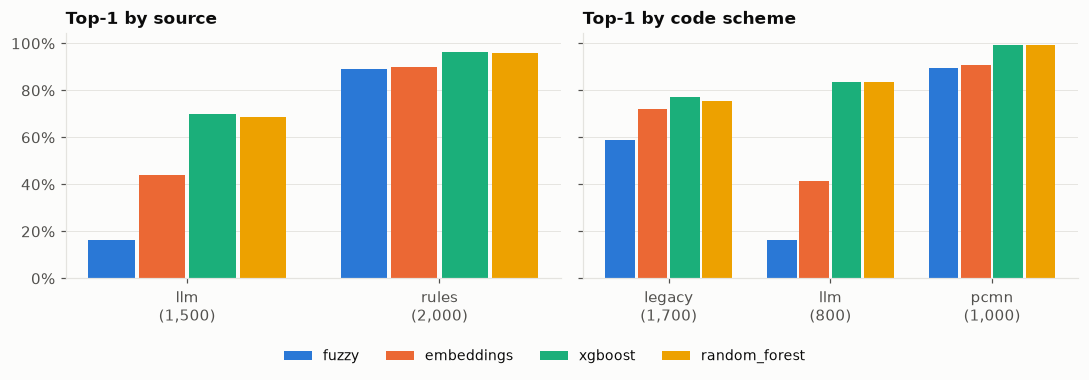

In [5]:
def segment_table(field):
    out = []
    for value in sorted({getattr(r, field) for r in dev}):
        s = np.array([getattr(r, field) == value for r in dev])
        for m in METHODS:
            a = auto[m] & s
            out.append({field: value, "accounts": int(s.sum()), "method": m, "top-1": right[m][s].mean(), "auto-mapped": a.sum() / s.sum(),
                        "precision of auto": right[m][a].mean() if a.any() else np.nan})
    return pd.DataFrame(out)


by_source = segment_table("source")
by_scheme = segment_table("code_scheme")
fmt = {"top-1": "{:.1%}", "auto-mapped": "{:.1%}", "precision of auto": "{:.1%}"}
display(by_source.pivot(index="method", columns="source", values=["top-1", "auto-mapped", "precision of auto"]).loc[METHODS].style.format("{:.1%}", na_rep="–"))
display(by_scheme.pivot(index="method", columns="code_scheme", values=["top-1", "auto-mapped", "precision of auto"]).loc[METHODS].style.format("{:.1%}", na_rep="–"))

segment = np.array([f"{r.source} · {r.code_scheme}" for r in dev])
cross = []
for value in sorted(set(segment)):
    s = segment == value
    for m in ("embeddings", "xgboost", "random_forest"):
        a = auto[m] & s
        cross.append({"segment": value, "accounts": int(s.sum()), "method": m, "auto-mapped": a.sum() / s.sum(),
                      "precision of auto": right[m][a].mean() if a.any() else np.nan, "wrong auto-mapped": int((a & ~right[m]).sum())})
cross = pd.DataFrame(cross)
display(cross.pivot(index=["segment", "accounts"], columns="method", values=["auto-mapped", "precision of auto", "wrong auto-mapped"])
        .style.format("{:.1%}", na_rep="–", subset=["auto-mapped", "precision of auto"]).format("{:.0f}", subset=["wrong auto-mapped"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (table, field) in zip(axes, ((by_source, "source"), (by_scheme, "code_scheme"))):
    values = sorted(table[field].unique())
    width = 0.8 / len(METHODS)
    for j, m in enumerate(METHODS):
        part = table[table.method == m].set_index(field).loc[values]
        bars = ax.bar(np.arange(len(values)) + (j - 1.5) * width, part["top-1"], width=width * 0.92, color=METHOD_COLORS[m], label=m)
    ax.set_xticks(np.arange(len(values)), [f"{v}\n({int(table[table[field] == v].accounts.iloc[0]):,})" for v in values])
    ax.yaxis.set_major_formatter(pct())
    ax.grid(axis="x", visible=False)
    ax.set_title(f"Top-1 by {field.replace('_', ' ')}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

- **Where the code gives the answer, the rerankers are nearly perfect:** PCMN codes 99.4% auto-mapped at 100% precision, LLM codes 83.6% at 100%. The embeddings baseline auto-maps 50% and 9% of those.
- **Where it doesn't (legacy codes), they still double the baseline,** at 64.5% against 32.4%, but at 95% precision instead of 98%.
- **The weak segment: LLM-written accounts with legacy codes** (700 dev accounts). XGBoost auto-maps 27.6% of them, and **36 of those 193 are wrong (81.3% precision).** The embeddings baseline auto-maps only 7.9% there, at 83.6%. The segment was already the weakest; the reranker sends more of it through.
- **Why the pooled bar allows it:** the prefix-coded accounts are so reliably right that the pooled 98% is reached with room to spare, so the threshold can sit lower. The hard segment then gets in below 98%. This is the same effect notebook 10 found for fuzzy on LLM-written accounts.

**What this means.** The bar stays pooled, as decided on 2026-11-06. This table goes with every reported result as the diagnostic. Two later steps target exactly this segment: the LLM method (Task 3.4), and the cascade, which sends a method's low-confidence accounts to the LLM (Task 3.6).

## 5. Which accounts the reranker fixes, and which it breaks

XGBoost against the embeddings baseline, per dev account (top-1, before any threshold):

In [6]:
fixed = right["xgboost"] & ~right["embeddings"]
broken = ~right["xgboost"] & right["embeddings"]
display(pd.crosstab(pd.Series(np.where(right["embeddings"], "embeddings right", "embeddings wrong"), name=""),
                    pd.Series(np.where(right["xgboost"], "XGBoost right", "XGBoost wrong"), name="")))


def examples(mask, n=8, seed=0):
    idx = np.random.default_rng(seed).choice(np.flatnonzero(mask), size=min(n, int(mask.sum())), replace=False)
    return pd.DataFrame([{
        "account": dev[j].name, "code": dev[j].code, "source": dev[j].source, "right group": f"{dev[j].target_code} {by_code[dev[j].target_code].name_en[:26]}",
        "embeddings pick": decisions["embeddings"][j].chosen_code, "XGBoost pick": decisions["xgboost"][j].chosen_code,
    } for j in sorted(idx)])


print(f"fixed by XGBoost: {fixed.sum()}  ({fixed[np.array([r.code_scheme != 'legacy' for r in dev])].sum()} of them with a code that starts with the group)")
display(examples(fixed).style.hide(axis="index"))
print(f"broken by XGBoost: {broken.sum()}")
display(examples(broken).style.hide(axis="index"))

,XGBoost right,XGBoost wrong
,,
embeddings right,2439,21
embeddings wrong,534,506


fixed by XGBoost: 534  (426 of them with a code that starts with the group)


account,code,source,right group,embeddings pick,XGBoost pick
MOINS-VALUES SUR RÉALISATION D,663000,rules,663 Capital Losses on Disposal,752,663
Resultaten uit de omrekeing van vreemde valuta,4640,rules,655 Foreign Currency Translati,755,655
Resultaten uit de omrekening van vreemde valuta / Ecarts de conversion des devises,5420,rules,655 Foreign Currency Translati,755,655
Stake 20%,282000,llm,282 Participating Interests in,280,282
Consulting & implementation revenue,700010,llm,700 Sales and Services Rendere,210,700
Meerwaarde verkoop bedrijfswagens,763000,llm,763 Capital Profits on Disposa,742,763
Geraamde VenB aanslagjaar,450000,llm,450 Estimated Taxes Payable,670,450
WV dubieuze overige vorderingen,419000,llm,419 Sundry Amounts Receivable,417,419


broken by XGBoost: 21


account,code,source,right group,embeddings pick,XGBoost pick
Provisions for Environmental Obligations,5000,rules,163 Provisions for Environment,163,637
Provisions pour grosses réparations et gros entretien,1370,rules,162 Provisions for Major Repai,162,636
Wisselresultaten,5290,rules,754 Exchange Differences,754,654
Resultaten uit de omrekening van vreemde valuta,5300,rules,755 Foreign Currency Translati,755,655
PROV. FOR ENVIRONMENTAL OBLIGA,6730,rules,163 Provisions for Environment,163,637
Resultaten uit de omrekening van vreemde valuta,6100,rules,755 Foreign Currency Translati,755,655
Achtergestelde lening zaakvoerder,2690,llm,170 Subordinated Loans (> 1 Ye,170,420
Aankoop handelsgoederen IC verlegd,1820,llm,604 Purchases of Goods for Res,604,349


- **534 accounts fixed, 21 broken.** 2,439 are right for both, and 506 are wrong for both (mostly accounts whose right group isn't on the shortlist at all: no reranker can fix those).
- **Most fixes, 426 of the 534, are accounts whose code starts with the right group.** "Stake 20%" (code 282000) is a participating interest (282), not 280. "Geraamde VenB aanslagjaar" (450000) is estimated taxes payable (450), not the tax charge (670). "MOINS-VALUES SUR RÉALISATION D" (663000) is a capital loss (663), not 752.
- **The breaks are mirror groups,** pairs whose official names are *identical* in all three languages: 163 and 637 are both *Provisions for Environmental Obligations* (the provision on the balance sheet, and the charge in the P&L), and 655 and 755 are both *Foreign Currency Translation Differences* (charge and income). With a legacy code like 5000 or 5300, nothing in the account says which one is meant, so any method is guessing. The same rule-based name "Resultaten uit de omrekening van vreemde valuta" shows up as a fix (code 4640, right group 655) and as a break (code 5300, right group 755).
- **What could tell them apart** is the context: the accounts around it in the company's chart. The LLM method gets the neighbouring account names (Task 3.4).

### Learning, or remembering names from train?

Rule-based companies reuse near-official names, so many dev names also occur in train. If the model only remembered them, it would be much better on those than on new names. Per method:

In [7]:
train_names = {r.name.casefold() for r in train}
seen = np.array([r.name.casefold() in train_names for r in dev])
display(pd.DataFrame([{"method": m, "name also in train": f"{right[m][seen].mean():.1%}", "name new": f"{right[m][~seen].mean():.1%}",
                       "gap": f"{(right[m][seen].mean() - right[m][~seen].mean()) * 100:.1f} pts",
                       "auto, new names": f"{auto[m][~seen].mean():.1%}", "precision, new names": f"{right[m][auto[m] & ~seen].mean():.1%}"}
                      for m in METHODS]).set_index("method"))
print(f"{seen.sum():,} of {len(dev):,} dev names also occur in train ({seen[np.array([r.source == 'rules' for r in dev])].mean():.0%} of rule-based, "
      f"{seen[np.array([r.source == 'llm' for r in dev])].mean():.0%} of LLM-written)")

,name also in train,name new,gap,"auto, new names","precision, new names"
method,,,,,
fuzzy,77.9%,38.8%,39.2 pts,8.7%,92.3%
embeddings,83.8%,57.3%,26.5 pts,18.3%,96.0%
xgboost,94.4%,75.9%,18.5 pts,66.3%,96.8%
random_forest,93.8%,74.8%,19.0 pts,66.2%,96.7%


1,712 of 3,500 dev names also occur in train (69% of rule-based, 22% of LLM-written)


- **Every method is better on names that also occur in train,** because those are the common, near-official names, and are easy for any method.
- **But the rerankers' gap is the smallest:** 18.5 points for XGBoost, against 26.5 for the embeddings and 39.2 for fuzzy. A model that memorized train names would show the *largest* gap.
- **On new names alone,** XGBoost auto-maps 66.3% at 96.8% precision, against 18.3% for the embeddings baseline.

## 6. Which features the models rely on

**Permutation importance on the held-out train companies:** shuffle one feature's column across all rows, so it carries no information, and measure how many points of top-1 the model loses (3 shuffles, averaged). It is measured the same way for both models, on the measure the method is judged by.

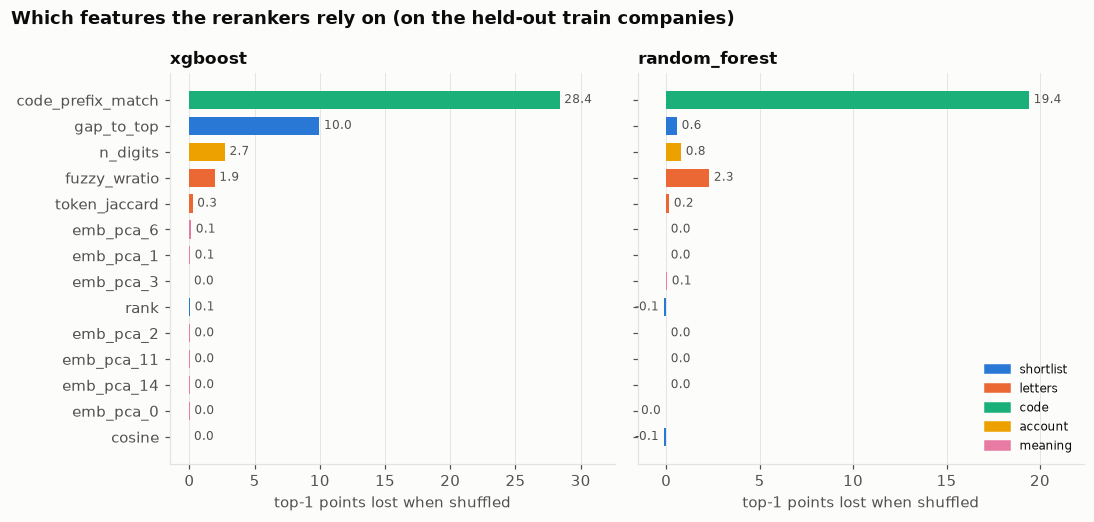

the 16 meaning features, each shuffled alone, summed: XGBoost -0.1 points, random forest -0.3 points


In [8]:
importance = pd.DataFrame({m: dict(mappers[m].method.feature_importance()) for m in ("xgboost", "random_forest")})
importance = importance.loc[importance.max(axis=1).sort_values(ascending=False).index]
FAMILY_COLORS = {"shortlist": "#2a78d6", "letters": "#eb6834", "code": "#1baf7a", "account": "#eda100", "meaning": "#e87ba4"}
FAMILY = {"cosine": "shortlist", "rank": "shortlist", "gap_to_top": "shortlist", "parent_cosine": "shortlist",
          "fuzzy_wratio": "letters", "token_jaccard": "letters", "code_prefix_match": "code", "class_digit_match": "code",
          "name_len": "account", "n_digits": "account", "is_bilingual": "account"}
top = importance.head(14).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True)
for ax, m in zip(axes, ("xgboost", "random_forest")):
    bars = ax.barh(top.index, top[m] * 100, color=[FAMILY_COLORS[FAMILY.get(f, "meaning")] for f in top.index], height=0.7)
    ax.bar_label(bars, labels=[f"{v * 100:.1f}".replace("-0.0", "0.0") for v in top[m]], padding=3, fontsize=8, color=INK_2)
    ax.set_xlim(-1.5, top[m].max() * 100 * 1.15)
    ax.set_title(m)
    ax.set_xlabel("top-1 points lost when shuffled")
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
axes[1].legend(handles, FAMILY_COLORS.keys(), loc="lower right", fontsize=8)
fig.suptitle("Which features the rerankers rely on (on the held-out train companies)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"the 16 meaning features, each shuffled alone, summed: XGBoost {importance.loc[[f'emb_pca_{i}' for i in range(16)], 'xgboost'].sum() * 100:.1f} points, "
      f"random forest {importance.loc[[f'emb_pca_{i}' for i in range(16)], 'random_forest'].sum() * 100:.1f} points")

- **The code prefix is by far the most important:** shuffling it costs XGBoost 28.4 points of top-1 and the forest 19.4. Then come `gap_to_top` (10.0 for XGBoost) and `n_digits` (2.7), which tells a PCMN-style code from a legacy one, and so how far to trust the prefix. After those, `fuzzy_wratio` (1.9; 2.3 for the forest).
- **Why the cosine, the rank and the meaning features show about 0:** a feature that another feature duplicates loses nothing when shuffled alone, because the duplicate still carries the information. The gap already holds the cosine's information, and each of the 16 meaning features shares it with the other 15. So "about 0 when shuffled alone" doesn't mean "useless". Section 7 removes them *together*, which costs 2.1 points of auto share.
- **A slightly negative value** (−0.1 for the forest's rank and cosine) means a shuffle happened to help a little: noise around 0.
- **The hold-out is 83% rule-based with half PCMN codes,** so these numbers say what matters *there*. On LLM-written accounts with legacy codes, the letters and the meaning carry more weight.

## 7. Two questions on the features: how many PCA features, and what the code is worth

Notebook 13 left one question open. 16 PCA features keep only 40% of the variation; would 64 do better? Here XGBoost is refitted with 0, 16 and 64 PCA features. A fourth variant has the **three code features set to 0** (`code_prefix_match`, `class_digit_match`, `n_digits`), which shows what the names alone are worth. Each is calibrated on dev exactly as `train.py` does. The differences are paired against the 16 variant, on the same accounts.

In [9]:
variants = {}
for n_pca in (0, 16, 64):
    start = time.time()
    reranker = refit if n_pca == config.models.mapping.n_pca else refit_xgboost(n_pca)
    cal = calibrate_on_dev(reranker.score(dev_accounts, dev_lists), dev, TARGET)
    variants[n_pca] = cal
    print(f"{n_pca:>2} PCA features: {time.time() - start:.0f} s")

CODE_FEATURES = ["code_prefix_match", "class_digit_match", "n_digits"]


class WithoutCode(PairFeaturizer):
    # The same features with the three code features set to 0: what the names alone are worth.

    def transform(self, accounts, candidates):
        out = super().transform(accounts, candidates)
        columns = [self.feature_names.index(f) for f in CODE_FEATURES]
        for m in out:
            m[:, columns] = 0
        return out


start = time.time()
no_code = PairwiseReranker("xgboost", WithoutCode(retriever, chart, n_pca=16), xgboost_model)
no_code.fit(train, train_lists)
variants["16, no code"] = calibrate_on_dev(no_code.score(dev_accounts, dev_lists), dev, TARGET)
print(f"16 PCA, no code features: {time.time() - start:.0f} s")

base = variants[16]
rows = []
for n_pca, cal in variants.items():
    row = {"variant": n_pca, "top-1": cal.right.mean(), "auto-mapped": cal.auto.mean(),
           "precision of auto": cal.right[cal.auto].mean() if cal.auto.any() else np.nan}
    if n_pca != 16:  # paired with the saved setting: the same accounts, so the companies' luck cancels
        for label, a, b in (("auto vs 16", cal.auto, base.auto), ("top-1 vs 16", cal.right, base.right)):
            d, lo, hi = paired_bootstrap_diff(a, b, groups=companies)
            row[label] = f"{d * 100:+.1f} pts ({lo * 100:+.1f} to {hi * 100:+.1f})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("variant").style.format({"top-1": "{:.1%}", "auto-mapped": "{:.1%}", "precision of auto": "{:.1%}"}, na_rep="–"))

legacy_llm = segment == "llm · legacy"
display(pd.DataFrame([{"variant": v, **{f"{seg}: auto": cal.auto[segment == seg].mean() for seg in sorted(set(segment))},
                       "llm · legacy: precision": cal.right[cal.auto & legacy_llm].mean() if (cal.auto & legacy_llm).any() else np.nan}
                      for v, cal in variants.items()]).set_index("variant").style.format("{:.1%}", na_rep="–"))

 0 PCA features: 6 s


16 PCA features: 1 s


64 PCA features: 11 s


16 PCA, no code features: 8 s


,top-1,auto-mapped,precision of auto,auto vs 16,top-1 vs 16
variant,,,,,
0,83.9%,76.5%,98.0%,-2.1 pts (-3.2 to -1.2),-1.1 pts (-1.7 to -0.5)
16,84.9%,78.7%,98.1%,–,–
64,84.9%,79.4%,98.1%,+0.7 pts (+0.1 to +1.4),+0.0 pts (-0.3 to +0.4)
"16, no code",76.5%,55.9%,98.0%,-22.7 pts (-29.0 to -17.0),-8.4 pts (-11.8 to -5.2)


,llm · legacy: auto,llm · llm: auto,rules · legacy: auto,rules · pcmn: auto,llm · legacy: precision
variant,,,,,
0,19.9%,83.5%,87.8%,99.4%,74.1%
16,27.3%,83.6%,89.9%,99.4%,82.2%
64,30.0%,83.6%,90.5%,99.4%,84.8%
"16, no code",14.9%,14.4%,85.7%,88.1%,92.3%


**How many PCA features.**
- **0 features costs 2.1 points of auto share** (interval −3.2 to −1.2) and 1.1 of top-1. The meaning features help, even though each alone showed about 0 in section 6.
- **64 features gain 0.7 points of auto share** (+0.1 to +1.4), with top-1 unchanged (+0.0). They help most on LLM-written legacy accounts: 30.0% auto-mapped at 84.8% precision, against 27.3% at 82.2%.
- **Decision: 16 stays for now.** The gain is about 25 accounts. Its interval only just clears 0, and it is the best of three variants tried on the same dev accounts, which makes it look a little better than it is. If Task 3.5 comes down to a close call, 64 is the first thing to retry: one line in `config/models.yaml` (`n_pca`) and a retrain.

(The 16 variant here auto-maps 78.7% against the saved model's 78.8%. That is one account, from the encoding noise explained in section 2.)

**What the code is worth.**
- **Without the code features, XGBoost auto-maps 55.9%,** against 78.7% with them. That is 22.7 points less, so most of the gain over the baselines is the code. Top-1 falls to 76.5%.
- **The names alone still beat both baselines by far:** 55.9% auto-mapped against 32.1% for the embeddings baseline, and top-1 76.5% against 70.3%. Combining the shortlist, the letters and the meaning is worth something on its own.
- **Without the code, the weak segment becomes more accurate:** LLM-written legacy accounts get 92.3% precision (14.9% auto-mapped) instead of 82.2%. With no prefix-coded accounts to carry the pooled bar, the threshold has to rise, and fewer hard accounts slip through.
- **A real company's codes decide which of these numbers applies.** A company that numbers by PCMN gets close to the prefix-coded results; one with its own numbering gets the legacy ones. That's why results are reported per code scheme, and why the family company chart (a private final test, later) matters.

## 8. Would more training data help? The learning curve

`python -m d1.evaluation.learning_curve --method xgboost random_forest` refits each model on 25%, 50%, 75% and 100% of the train companies. Whole companies are taken, with the same rule-based/LLM mix, and each share contains the smaller ones. Each point is calibrated on dev exactly as in training. The report is in `reports/learning_curve.md`.

**The decision rule, fixed in the plan before running it:** if the 100% point beats the 75% point by more than half its interval's width, double the rule-based train companies and rerun. Otherwise more data has stopped helping.

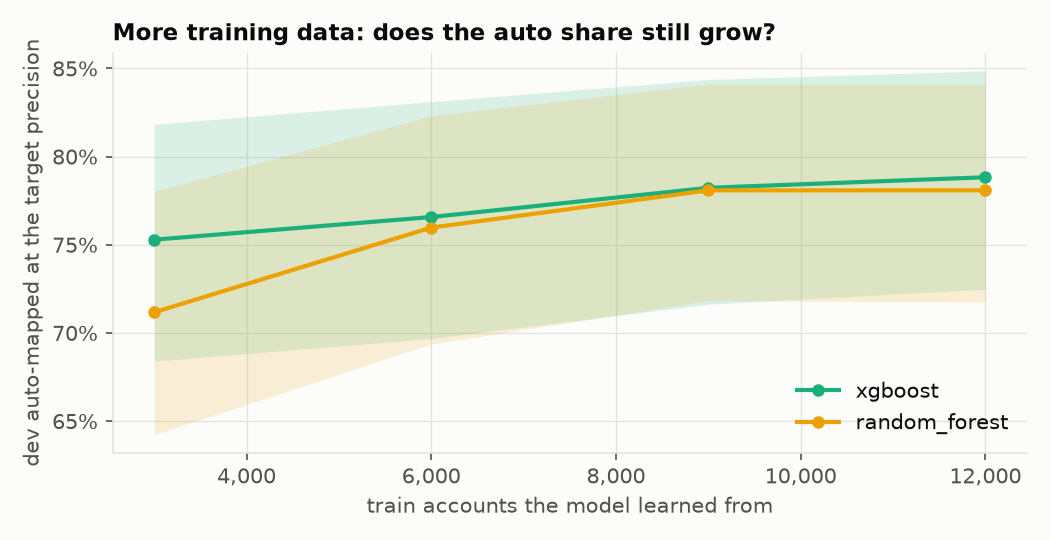

method,share of train,accounts,top-1,auto-mapped,95% interval,auto (rules),auto (LLM)
xgboost,25%,"3,000",83.6%,75.3%,68.4% – 81.8%,92.7%,52.1%
xgboost,50%,"5,999",84.2%,76.6%,69.7% – 83.1%,93.8%,53.7%
xgboost,75%,"8,999",84.4%,78.2%,71.6% – 84.4%,94.8%,56.2%
xgboost,100%,"11,999",84.9%,78.8%,72.5% – 84.9%,94.8%,57.5%
random_forest,25%,"3,000",83.1%,71.2%,64.2% – 78.0%,91.5%,44.1%
random_forest,50%,"5,999",83.7%,76.0%,69.4% – 82.3%,93.2%,53.0%
random_forest,75%,"8,999",83.7%,78.1%,71.8% – 84.1%,94.1%,56.7%
random_forest,100%,"11,999",84.1%,78.1%,71.7% – 84.1%,94.0%,56.8%


more data still helps: {'xgboost': False, 'random_forest': False}


In [10]:
curve = json.loads((config.root / "reports" / "learning_curve.json").read_text())
display(Image(filename=str(config.root / "reports" / "learning_curve.png"), width=640))
display(pd.DataFrame([{"method": m, "share of train": p["fraction"], "accounts": p["n_train_accounts"], "top-1": p["top1"],
                       "auto-mapped": p["auto_share"], "95% interval": f"{p['auto_share_ci'][0]:.1%} – {p['auto_share_ci'][1]:.1%}",
                       "auto (rules)": p["by_source"]["rules"]["auto_share"], "auto (LLM)": p["by_source"]["llm"]["auto_share"]}
                      for m, points in curve["curves"].items() for p in points])
        .style.format({"share of train": "{:.0%}", "accounts": "{:,}", "top-1": "{:.1%}", "auto-mapped": "{:.1%}", "auto (rules)": "{:.1%}", "auto (LLM)": "{:.1%}"}).hide(axis="index"))
print("more data still helps:", curve["more_data_helps"])

- **From 25% to 100% of the companies:** XGBoost goes from 75.3% to 78.8% auto-mapped, and the forest from 71.2% to 78.1%. The forest needs more data to get there, which fits: its trees grow independently and deep, so it needs more examples per pattern.
- **From 75% to 100%:** +0.6 points for XGBoost and +0.0 for the forest, against an interval half-width of 6.2. **More data stopped helping, so `rule_companies` stays at 200.** The README says so.
- **Only the LLM-written accounts still creep up** (XGBoost 56.2% → 57.5%). The rule would add *rule-based* companies, which wouldn't help those; more LLM companies would cost calls. The weak segment needs a better method (Tasks 3.4 and 3.6), not more of the same data.

## 9. What is *not* happening

- **Dev never trains the models.** They learn from train only. Early stopping and feature importance use 10% of the *train* companies, never dev. Dev only calibrates the scores and chooses the threshold, exactly as for the baselines.
- **The test split is not touched.** Every number here is on dev.
- **No method is chosen yet.** Laya and the LLM come next (Tasks 3.3 and 3.4), and the comparison in Task 3.5 picks the best single method, with intervals and cost.
- **No hyperparameter search.** Both models use the plan's fixed settings. Only the number of XGBoost trees is chosen, by early stopping on the train hold-out. Tuning on dev would make the dev numbers optimistic.
- **No threshold per segment.** The 98% bar stays pooled over all accounts (decided 2026-11-06). Section 4 shows what that hides for LLM-written accounts with legacy codes, as a diagnostic.